In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
datos = pd.read_excel("datos cafe.xlsx")

# Eliminar filas vacias
datos = datos.dropna(subset=["Fecha", "Cafe verde (g)"])

# Organizar fechas (formato dia/mes/año)
datos["Fecha"] = pd.to_datetime(datos["Fecha"], dayfirst=True)

# Ordenar datos
datos = datos.sort_values("Fecha")

In [5]:
datos["Perdida calculada (g)"] = ( datos["Cafe verde (g)"] - datos["Cafe tostado (g)"])

datos["Perdida porcentual (%)"] = (datos["Perdida calculada (g)"] / datos["Cafe verde (g)"]) * 100

datos["Tiempo (dias)"] = (datos["Fecha"] - datos["Fecha"].min()).dt.days

print("DATOS ORGANIZADOS")
print(datos[[
    "Fecha",
    "Cafe verde (g)",
    "Cafe tostado (g)",
    "Perdida calculada (g)",
    "Perdida porcentual (%)",
    "Tiempo (dias)"]])

DATOS ORGANIZADOS
       Fecha  Cafe verde (g)  Cafe tostado (g)  Perdida calculada (g)  \
0 2026-10-17            4000              3400                    600   
1 2026-10-24            4100              3500                    600   
2 2026-10-31            3950              3345                    605   
3 2026-11-07            4050              3450                    600   
4 2026-11-14            4000              3410                    590   

   Perdida porcentual (%)  Tiempo (dias)  
0               15.000000              0  
1               14.634146              7  
2               15.316456             14  
3               14.814815             21  
4               14.750000             28  


In [6]:
import numpy as np
import pandas as pd

datos = pd.read_excel("datos cafe.xlsx")
datos["Fecha"] = pd.to_datetime(datos["Fecha"], dayfirst=True)
datos = datos.sort_values("Fecha").reset_index(drop=True)
datos

,Fecha,Cafe verde (g),Cafe tostado (g)
0,2026-10-17,4000,3400
1,2026-10-24,4100,3500
2,2026-10-31,3950,3345
3,2026-11-07,4050,3450
4,2026-11-14,4000,3410


In [7]:
datos["Tiempo (dias)"] = (datos["Fecha"] - datos["Fecha"].iloc[0]).dt.days
datos["Perdida porcentual (%)"] = (datos["Cafe verde (g)"] - datos["Cafe tostado (g)"]) / datos["Cafe verde (g)"] * 100
datos

,Fecha,Cafe verde (g),Cafe tostado (g),Tiempo (dias),Perdida porcentual (%)
0,2026-10-17,4000,3400,0,15.000000
1,2026-10-24,4100,3500,7,14.634146
2,2026-10-31,3950,3345,14,15.316456
3,2026-11-07,4050,3450,21,14.814815
4,2026-11-14,4000,3410,28,14.750000


In [8]:
x = datos["Tiempo (dias)"].to_numpy()
y = datos["Perdida porcentual (%)"].to_numpy()

A = np.column_stack((x, np.ones(len(x))))
m, b = np.linalg.lstsq(A, y, rcond=None)[0]

In [9]:
y_ajustada = m*x + b

SSE = np.sum((y - y_ajustada)**2)
SST = np.sum((y - np.mean(y))**2)
R2 = 1 - SSE/SST

print("\nRESULTADOS DE MINIMOS CUADRADOS")
print("Pendiente:", m)
print("Intercepto:", b)
print(f"Ecuacion: P(t) = {m:.5f}t + {b:.5f}")
print("R2:", R2)


RESULTADOS DE MINIMOS CUADRADOS
Pendiente: -0.004561878952122412
Intercepto: 14.966949675825866
Ecuacion: P(t) = -0.00456t + 14.96695
R2: 0.0359283093711259


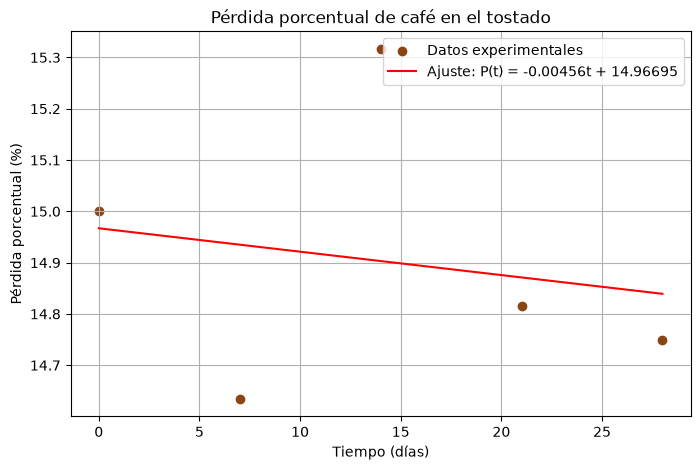

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="saddlebrown", label="Datos experimentales")
plt.plot(x, y_ajustada, color="red", label=f"Ajuste: P(t) = {m:.5f}t + {b:.5f}")

plt.xlabel("Tiempo (días)")
plt.ylabel("Pérdida porcentual (%)")
plt.title("Pérdida porcentual de café en el tostado")
plt.legend()
plt.grid(True)
plt.show()

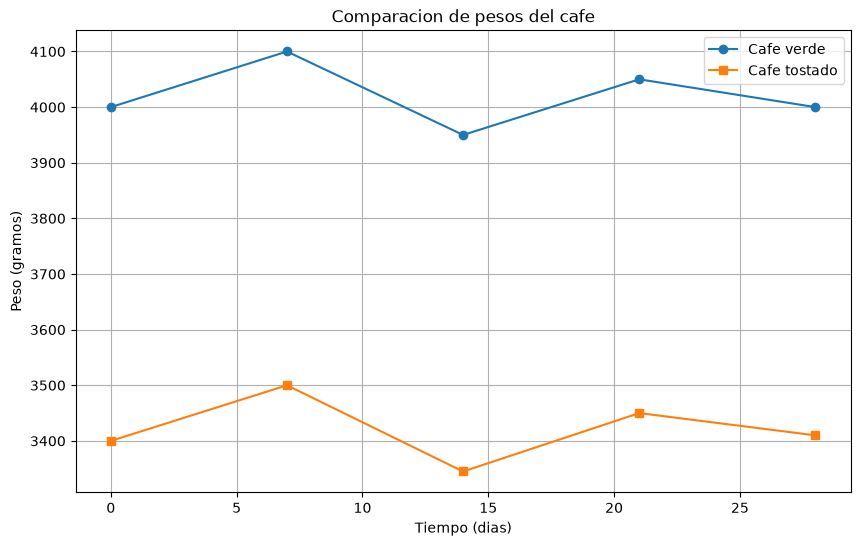

In [11]:
plt.figure(figsize=(10,6))
plt.plot(datos["Tiempo (dias)"], datos["Cafe verde (g)"],
         marker="o", label="Cafe verde")
plt.plot(datos["Tiempo (dias)"], datos["Cafe tostado (g)"],
         marker="s", label="Cafe tostado")
plt.title("Comparacion de pesos del cafe")
plt.xlabel("Tiempo (dias)")
plt.ylabel("Peso (gramos)")
plt.legend()
plt.grid()
plt.show()

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

datos = pd.read_excel("datos cafe.xlsx")

print(datos.head())

        Fecha  Cafe verde (g)  Cafe tostado (g)
0  17/10/2026            4000              3400
1  24/10/2026            4100              3500
2  31/10/2026            3950              3345
3  07/11/2026            4050              3450
4  14/11/2026            4000              3410


Ecuación: y = 1.0115x + -645.3846
R² = 0.9912
Predicción: con 4200 g de café verde -> 3603.08 g tostado


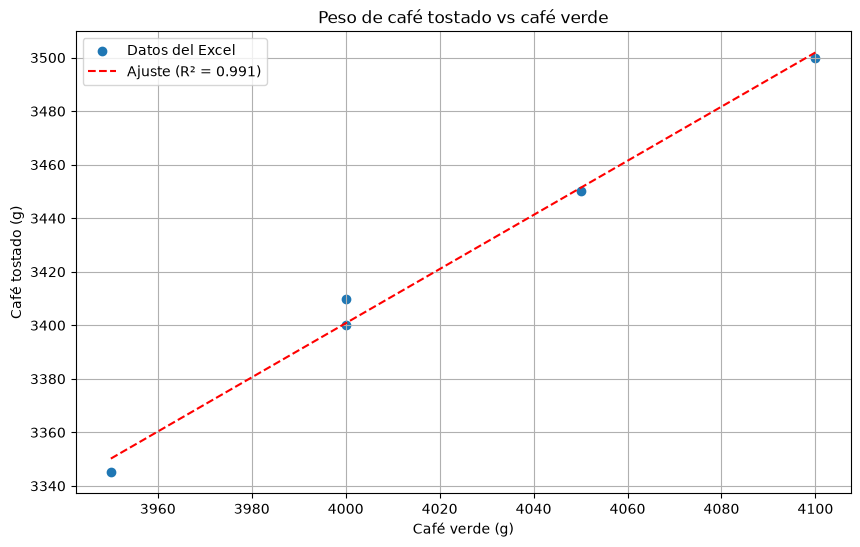

In [13]:

# Obtener los datos del Excel
xv = datos["Cafe verde (g)"].to_numpy()
yt = datos["Cafe tostado (g)"].to_numpy()

# Calcular la regresión lineal
m2, b2 = np.polyfit(xv, yt, 1)

# Calcular el coeficiente de determinación R²
predicciones = m2 * xv + b2
ss_res = np.sum((yt - predicciones)**2)
ss_tot = np.sum((yt - np.mean(yt))**2)
R2_2 = 1 - (ss_res / ss_tot)

# Mostrar la ecuación
print(f"Ecuación: y = {m2:.4f}x + {b2:.4f}")
print(f"R² = {R2_2:.4f}")

# Predicción para un lote nuevo
verde_nuevo = 4200
print(f"Predicción: con {verde_nuevo} g de café verde -> {m2*verde_nuevo + b2:.2f} g tostado")

# Crear gráfica
xs = np.linspace(xv.min(), xv.max(), 100)

plt.figure(figsize=(10,6))
plt.scatter(xv, yt, label="Datos del Excel")
plt.plot(xs, m2*xs + b2, "--", color="red", label=f"Ajuste (R² = {R2_2:.3f})")
plt.title("Peso de café tostado vs café verde")
plt.xlabel("Café verde (g)")
plt.ylabel("Café tostado (g)")
plt.legend()
plt.grid()
plt.show()



ESTADISTICA DE LA PERDIDA DE MASA
Promedio:            14.90 %
Desviacion estandar: 0.27 %
Minimo / Maximo:     14.63 % / 15.32 %
Coef. de variacion:  1.79 %
Rendimiento medio:   85.10 %


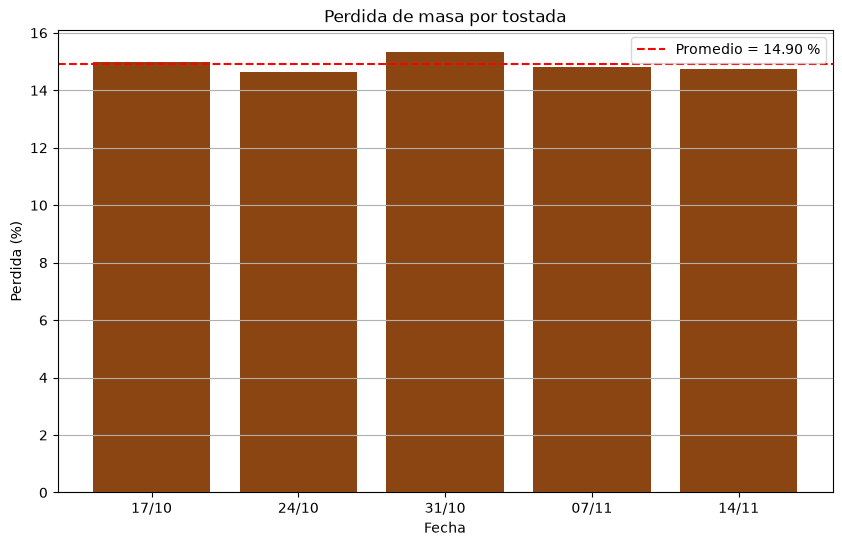

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Si aún no cargaste el archivo en esta sesión:
# datos = pd.read_excel("datos cafe.xlsx")

datos["Fecha"] = pd.to_datetime(datos["Fecha"], dayfirst=True, errors="coerce")

datos["Perdida calculada (g)"] = datos["Cafe verde (g)"] - datos["Cafe tostado (g)"]
datos["Perdida porcentual (%)"] = datos["Perdida calculada (g)"] / datos["Cafe verde (g)"] * 100
datos["Rendimiento (%)"] = datos["Cafe tostado (g)"] / datos["Cafe verde (g)"] * 100

perdida = datos["Perdida porcentual (%)"]
promedio = perdida.mean()
desv = perdida.std()
cv = desv / promedio * 100

print("\nESTADISTICA DE LA PERDIDA DE MASA")
print(f"Promedio:            {promedio:.2f} %")
print(f"Desviacion estandar: {desv:.2f} %")
print(f"Minimo / Maximo:     {perdida.min():.2f} % / {perdida.max():.2f} %")
print(f"Coef. de variacion:  {cv:.2f} %")
print(f"Rendimiento medio:   {datos['Rendimiento (%)'].mean():.2f} %")

plt.figure(figsize=(10, 6))
plt.bar(datos["Fecha"].dt.strftime("%d/%m"), perdida, color="saddlebrown")
plt.axhline(promedio, color="red", linestyle="--", label=f"Promedio = {promedio:.2f} %")
plt.title("Perdida de masa por tostada")
plt.xlabel("Fecha")
plt.ylabel("Perdida (%)")
plt.legend()
plt.grid(axis="y")
plt.show()

In [15]:
datos.to_excel("resultados_cafe.xlsx", index=False)
print("Archivo Excel generado correctamente")

Archivo Excel generado correctamente
